# 视觉信息支持与重量—距离对应关系

先跑开发：默认 Gemma-12B，`PHASE='development'`；完成后用全新 GPU 运行时改为 Qwen-27B，再从头运行。

[实验设置与运行说明](../../../docs/experiment_notes/90_followup_visual_and_relation_use/e935964a6720cf25.md)


In [ ]:
# Notebook utilities: support/visualtorque_checks.py
import base64 as _vt_base64, gzip as _vt_gzip, sys as _vt_sys, types as _vt_types
_vt_source = _vt_gzip.decompress(_vt_base64.b64decode("H4sIAAAAAAACCo1Y647bthL+76dgtziwtLGVTZAGqFs3J8BJkABJESCLoqjXFWiJsnmWElWS2qx7Afo0fbA+SWd4kSnJ23Z/JBLnPvPNcOSLi4vXXDBSHFhxqwltStJIw3ZS3pKS61bQI+kMF9xwpjPyrSS1LJkgUhF23zLFa9YYUrKWNSVrCmS6uLiY8bqVypCqawojpdDh4ED1QfBdeFUsPOmjnlVK1uRgapG1VGmmiKe9uX7/7oM9cSwtNagkkD/A62w2K1lFKgglRxsJ8qSrGYG/ku+ZNmQdjGf6QJ9+8TxJLfUTNwerwolkEiJJ5mo3TwnVINKUgjk9+FdB3MWha24Jbwg3TCWC1ruSrjxnphgtkydXT5+RS4L/pQuym8/Tk4aTR1nXltSwxOpzzihmOtUE+oHduydw1cXnPM8xzDhCLzZ35NWcPBpnYiqf7455Q2uW2JepstjUiQX0AAFyGZFnljw9diZ3R8M0UhMIlj7s8Kg4lvlMBhqpair4z9ZgckdFx0Z+G+WPoRa1vGOtYhW/T3pbqCl/8/LjG3BXsayQdYsxqnny4uvPNi+XP9Dlz1fLL/NtmrxYbeCJLquXy9fbX54/++3X+P3Z1W/AMhQB7fn1q++v8/dv37/6CBaSuWH35jH0EW/mC+LeEOP9S03VbSk/NfMQInpEC5MjNcF/FjY5TK+/lU2IFprs4wHQz5rQpqz0bAsiW8NlQ4U4klvGWt7sCYVY75jSfAfNLqC7u9Y2qoUjGFUMdBQsqakpDhFcbSohDnue7ZXsWt84+KfRBaBars3qydUWKjn/8/c/sKLucPl8te35eeV9JFzjnCEY0bA3eOW1QoN5XhxK7nFjSVvymTc5FI1QYKkD4lDBesTRgx6oMZosUDLd7RKfoAXBimCpCkG1Jvl33Ob0Got1GlRh9EBm85w33OR5opmonHgoaJRn3cEwTdKs5y5kA/UyeXGgChCs16+p0CxKPWjLnDL7GGpvX0CogbaBMGNzC7LZDuVlVWlmkG9zdZ6UgTyM9qTO8N/UDsAaawOtU/GmtDNwfoPYtokZOSiQTgUYwErP+qS4aZlrQ5UxdB9yQ/cLQo1RcWYAEHCOJqGHC8Vbg62jzVGw8VwdmQSxiUWIYmBvami9Huj5Wwtng8LR5Q1EIy9g+0HVDnH9kSthCUYG8wA1DiqextqDEPQHMg4NCN4AfAspurohPsg9M63UUUfbILEqgcPjYIPSZEmeYIc7HdPEeNhltMV1IEmsooXX94gIuFltRhbB0XQ883Ay/t3Me8foHbMQ4bvOIKTBr1uEvUUGPiAw3MzgNd0zmwhAjwH1/cTz+8V62L6D1oz4soqxMnF9H50WQmrmU4dt4aOFyBd+bNo2wakL4kHIpSgCBer1jbpZWR3bMDzhf3sMKv0Q9WMJT0eZC9fIg9n7nLyDVAFQteENxQtCg7oa7iXSaQo5WIC/hehKvC5sVomRVs8S94SSgGe8AlM6C1mwkwMGAdw/3OANerO9STY/ptvLm/TXgzGtfrF6/Hjz443++pvtozTMiMEKMM/+L3mD6TGIYE7+Q54SBqNuiPvW5nYM+egPK8AXxOlpoApdDT1mmJXUE6DZ/LpFYUFq2GLXw4t6mj+7y0LWoo5EtKLTKI9zI7rdhyGE4kyZ+9t/GvPMNzUgtAFcNEXvr+DaRAj6nDS7CvciQ+ASqTmUhZK6E7i2Q9PCRoQlhWLu8EUqrCV2CFRU0WPW68FC2IkTiuL2qOiS1KAU6CEViZOY1sUX1wk4eKArOsF1BNCs19cKNGN0XilMLG/e5uF0O3tVvUmfAm/xfH4g4jTWM+oUKICfo9Mq9zGWvHDT9tTgtnKArWjDG8z2QHc6xtMdzzbIso0Q5GAYEx0ahykdpPO0evzPLX4fDXx01M5cfsd1RwUU+acOr1ekgDnM9uyhjcRxxbsIzvKTsHs4iX9ScH1F28wDkpnjm2yz6QQmeC/4rWpgw0HGGbLP6fBDzKIb8m1pZ+5p5wBSI82V6OCjCOmRtrD+xe47xjROG9yWePX0mcO5ONXiuZJYm+f1SMxhoYNiHjxRJ5dU7eHuury8/YRPYeJAjCjmdx9Tys7vPiVTKl5++lr1to86mIyXD8cW7d7hg/8k6N2dn0MSGHdb6DjZI6OLETa91n4I4/chbEC5/3JJYP4xBcBn5iDL3GmAPHT424K3JRXfw7UlohjPSdlODoOzl4GAbbCQz17Y0yaRep/OhOoXNPv+3/6XDUAZbXWvL+3h0nY7mNOHB2rrXcSTYTLxBL8bB9MKD2FDh8XJats8WW1PhYU+qfp0IVacoaFadxbmmnflDMcmKIqnlPVhTJ+0cUjBJGKXMp+P7Gy6w4yK4XSuvl5JAJId/EL0QIKRKcRoZXxtsTb9VUs24viVuyDAWfzFwm2NxYGLctkqWTAYskJC1sDIEW4gIfoF0n6lgq0ArWidU8dh5u1PVm8/HCGKJvxkBSjMeWuPTmW8L1hryFvL8Uopqc59HzhURh/g6MQ6Vpik/+DhRNFkHDkN4y616jL/lkMloHd8PXAq4V05/xeSBygCsNvhnLu1xX4yoY7wChid92EMxhNqemA65aj5TN8667CHN7C6KraH5Qm/WVvFctU1eQFUkBonIR3JP2gxhq5PrX3/C0ov0eJaFQAA"))
_vt_checks = _vt_types.ModuleType("visualtorque_checks")
exec(compile(_vt_source, "<visualtorque_checks>", "exec"), _vt_checks.__dict__)
_vt_sys.modules["visualtorque_checks"] = _vt_checks
_vt_checks.install_display()
del _vt_source


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready.


In [2]:
%%cell_progress 1/13 Mount Drive and locate project
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate project:   0%|          | 0/13 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/13 Choose model and development or validation phase
MODEL_KEY = 'qwen27b'   # gemma12b first; then qwen27b in a FRESH GPU runtime.
PHASE = 'development'   # After BOTH development runs: change to 'validation'.
RUN_ID = 'main'
N_VALIDATION = 96        # 96 or 128; decide BEFORE the first validation run.
SEED = 2026091801
SOURCE_HISTORY_RUN_ID = 'main'
EXTRA_HISTORY_FILES = [] # Optional explicit old support.json / scenes.jsonl / snapshot paths.
# No recursive history scan, no layer search, no interventions in this notebook.


Choose model and development or validation phase:   8%|7         | 1/13 [00:00<?, ?cell/s]

In [4]:
%%cell_progress 3/13 Install pinned inference dependencies
import importlib
import os

os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'hf_xet>=1.1', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'Pillow==11.3.0',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install pinned inference dependencies:  15%|#5        | 2/13 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [5]:
%%cell_progress 4/13 Load experimental design and analysis
"""CPU design, rendering, prompts and family-paired analysis for information support."""
from __future__ import annotations

import hashlib
import itertools
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

SCHEMA = 'visual-information-support-v1'
CONDITIONS = ('image', 'image_weight', 'image_distance', 'image_full', 'text_full', 'legacy_image')
STRATA = ('congruent', 'balanced', 'equal_weight_distance', 'weight_conflict', 'binding_swap')
LABELS = ('A', 'B', 'C')
SEMANTICS = ('left', 'balanced', 'right')
SEMANTIC_TEXT = {'left': 'left side', 'balanced': 'equal', 'right': 'right side'}
RULE_TEXT = ('Each square is one unit of weight. Distance is measured in tick '
             'intervals from the center pivot. Torque equals weight times distance. '
             'Total torque on a side is the sum over stacks on that side.')
REPLY_TEXT = ('Do not explain your reasoning. Reply with exactly one option letter '
              'and nothing else. Valid replies are: A, B, C.')
MODEL_SPECS = {
    'gemma12b': dict(model_id='google/gemma-4-12B-it',
                    revision='707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7'),
    'qwen27b': dict(model_id='Qwen/Qwen3.5-27B',
                   revision='373612cb4f9288fcf550b526d86d85febedd9801'),
}


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False,
                                    allow_nan=False).encode()).hexdigest()


from visualtorque_checks import file_hash


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def save_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    tmp.replace(path)


def freeze(path, obj):
    if Path(path).exists():
        assert read_json(path) == obj, f'Frozen configuration changed: {path}. Use a new RUN_ID.'
    else:
        save_json(path, obj)
    return digest(obj)


def signature(stacks):
    direct = tuple(sorted((s['side'], int(s['distance']), int(s['units'])) for s in stacks))
    mirror = tuple(sorted(('right' if s == 'left' else 'left', d, w) for s, d, w in direct))
    return min(direct, mirror)


def geometries_in(obj):
    found = set()
    if isinstance(obj, dict):
        if isinstance(obj.get('stacks'), list) and obj['stacks']:
            stacks = obj['stacks']
            if all(isinstance(s, dict) and {'side', 'distance', 'units'} <= s.keys() for s in stacks):
                found.add(signature(stacks))
        for key, value in obj.items():
            if key == 'signatures' and isinstance(value, list):
                for sig in value:
                    found.add(signature([dict(side=s, distance=d, units=w) for s, d, w in sig]))
            elif key != 'stacks':
                found.update(geometries_in(value))
    elif isinstance(obj, list):
        for item in obj:
            found.update(geometries_in(item))
    return found


def load_history(project, run_root, source_run='main', extra_files=(), progress=print):
    """Read only explicit old supports/snapshots and shallow dataset manifests; no recursive Drive walk."""
    project, run_root = Path(project), Path(run_root)
    lock = run_root / 'historical_exclusion.json'
    if lock.exists():
        old = read_json(lock)
        assert old['source_run'] == source_run and old['extra_files'] == [str(p) for p in extra_files]
        for name, sha in old['files'].items():
            assert file_hash(name) == sha, 'Historical input changed: ' + name
        progress(f"Reusing frozen exclusions: {len(old['signatures'])} geometries; no directory scan.")
        return geometries_in(old)
    paths = set()
    data = project / 'data'
    if data.exists():
        paths.update(data.glob('*/scenes.jsonl'))
        if (data / 'scenes.jsonl').is_file():
            paths.add(data / 'scenes.jsonl')
    results = project / 'results'
    if results.exists():
        # Only top-level experiment directories and this known run, never activation shards.
        for experiment in results.iterdir():
            if experiment.is_dir() and experiment.resolve() != run_root.parent.resolve():
                for folder in (experiment, experiment / source_run):
                    for name in ('historical_geometry_snapshot.json', 'support.json', 'scenes.jsonl'):
                        if (folder / name).is_file():
                            paths.add(folder / name)
    for name in extra_files:
        p = Path(name)
        assert p.is_file(), f'EXTRA_HISTORY_FILES must name files: {p}'
        paths.add(p)
    assert paths, 'No historical manifests found. Restore old support/snapshot files, or set EXTRA_HISTORY_FILES.'
    signatures, hashes = set(), {}
    for i, path in enumerate(sorted(paths)):
        progress(f'Read historical manifest {i+1}/{len(paths)}: {path.name}')
        h = hashlib.sha256()
        with path.open('rb') as stream:
            if path.suffix == '.jsonl':
                for line in stream:
                    h.update(line)
                    if line.strip():
                        signatures.update(geometries_in(json.loads(line.decode('utf-8-sig'))))
            else:
                raw = stream.read()
                h.update(raw)
                signatures.update(geometries_in(json.loads(raw.decode('utf-8-sig'))))
        hashes[str(path)] = h.hexdigest()
    assert signatures, 'No usable historical geometry was found in the selected manifests.'
    save_json(lock, dict(source_run=source_run, extra_files=[str(p) for p in extra_files],
                         files=hashes, signatures=[[list(t) for t in sig] for sig in sorted(signatures)],
                         scope='Listed manifests/snapshots only; unseen ZIPs or unlisted runs are not certified disjoint.'))
    return signatures


def scene_features(stacks):
    w = {s: sum(x['units'] for x in stacks if x['side'] == s) for s in ('left', 'right')}
    torque = {s: sum(x['units'] * x['distance'] for x in stacks if x['side'] == s)
              for s in ('left', 'right')}
    delta = torque['left'] - torque['right']
    weight = w['left'] - w['right']
    outcome = lambda x: 'left' if x > 0 else 'right' if x < 0 else 'balanced'
    return dict(left_torque=torque['left'], right_torque=torque['right'], net_torque=delta,
                weight_score=weight, outcome=outcome(delta), weight_outcome=outcome(weight))


def allocation(n):
    assert isinstance(n, int) and n >= 32 and n % 8 == 0
    return dict(congruent=n//8, balanced=n//8, equal_weight_distance=n//4,
                weight_conflict=n//4, binding_swap=n//4)


def _candidate(rng, stratum):
    dl, dr = [sorted(rng.choice(np.arange(1, 7), 2, replace=False).tolist()) for _ in range(2)]
    wl, wr = rng.integers(1, 7, size=(2, 2)).tolist()
    if stratum == 'equal_weight_distance':
        wr = wl.copy()
        if not (all(a > b for a, b in zip(dl, dr)) or all(a < b for a, b in zip(dl, dr))):
            return None
    stacks = [dict(side=side, distance=d, units=w) for side, distances, weights in
              [('left', dl, wl), ('right', dr, wr)] for d, w in zip(distances, weights)]
    f = scene_features(stacks)
    if stratum == 'congruent':
        distance_delta = sum(dl) - sum(dr)
        if not (f['weight_score'] * f['net_torque'] > 0 and distance_delta * f['net_torque'] > 0):
            return None
    elif stratum == 'balanced' and f['net_torque'] != 0:
        return None
    elif stratum == 'weight_conflict' and f['weight_score'] * f['net_torque'] >= 0:
        return None
    roles = {'base': stacks}
    if stratum == 'binding_swap':
        swapped = [dict(s) for s in stacks]
        swapped[0]['units'], swapped[1]['units'] = swapped[1]['units'], swapped[0]['units']
        if f['net_torque'] * scene_features(swapped)['net_torque'] >= 0:
            return None
        roles['swapped'] = swapped
    return roles


def generate_families(n, seed, excluded, phase):
    rng = np.random.default_rng(seed)
    used = set(excluded)
    families = []
    for stratum, count in allocation(n).items():
        accepted = 0
        for attempt in range(300000):
            roles = _candidate(rng, stratum)
            if roles is None:
                continue
            sigs = {signature(s) for s in roles.values()}
            if len(sigs) != len(roles) or sigs & used:
                continue
            fid = 'vis_' + digest([SCHEMA, phase, stratum, sorted(sigs)])[:16]
            slot_ids = np.random.default_rng(int(digest([fid, 'ids'])[:16], 16)).permutation(4).tolist()
            records = []
            for role, stacks in roles.items():
                for mirror in (False, True):
                    actual = [dict(s, stack_id=f'S{slot_ids[i]+1}',
                                   side=('right' if s['side'] == 'left' else 'left') if mirror else s['side'])
                              for i, s in enumerate(stacks)]
                    sid = f'{fid}__{role}__m{int(mirror)}'
                    records.append(dict(scene_id=sid, role=role, mirror=mirror,
                                        stacks=actual, features=scene_features(actual)))
            families.append(dict(family_id=fid, stratum=stratum, phase=phase, scenes=records))
            used.update(sigs)
            accepted += 1
            if accepted == count:
                break
        assert accepted == count, f'Insufficient unused {stratum} geometries: {accepted}/{count}; do not relax exclusions.'
    families.sort(key=lambda f: digest([seed, f['family_id']]))
    validate_families(families, excluded)
    return families


def validate_families(families, excluded=()):
    used = set(excluded)
    assert len({f['family_id'] for f in families}) == len(families)
    for family in families:
        base = [s for s in family['scenes'] if not s['mirror']]
        sigs = {signature(s['stacks']) for s in base}
        assert len(sigs) == len(base) and not sigs & used
        used.update(sigs)
        for scene in family['scenes']:
            assert scene_features(scene['stacks']) == scene['features']
            assert len(scene['stacks']) == 4
            assert len({(s['side'], s['distance']) for s in scene['stacks']}) == 4
            assert len({s['stack_id'] for s in scene['stacks']}) == 4
            assert all(1 <= s['units'] <= 6 and 1 <= s['distance'] <= 6 for s in scene['stacks'])
        if family['stratum'] == 'binding_swap':
            a, b = base
            assert a['features']['net_torque'] * b['features']['net_torque'] < 0
            for side in ('left', 'right'):
                aa = [s for s in a['stacks'] if s['side'] == side]
                bb = [s for s in b['stacks'] if s['side'] == side]
                assert sorted(s['units'] for s in aa) == sorted(s['units'] for s in bb)
                assert sorted(s['distance'] for s in aa) == sorted(s['distance'] for s in bb)
            assert {s['stack_id']: (s['side'], s['distance']) for s in a['stacks']} == {
                s['stack_id']: (s['side'], s['distance']) for s in b['stacks']}


def mappings_for(family_id):
    offset = int(digest([family_id, 'mapping'])[:8], 16) % 3
    return [tuple(SEMANTICS[(i + k + offset) % 3] for i in range(3)) for k in range(3)]


def public_fields(scene, condition):
    assert condition in CONDITIONS
    full = condition in ('image_full', 'text_full')
    return [dict(stack_id=s['stack_id'], side=s['side'],
                 weight=s['units'] if full or condition == 'image_weight' else 'not provided',
                 distance=s['distance'] if full or condition == 'image_distance' else 'not provided')
            for s in sorted(scene['stacks'], key=lambda s: s['stack_id'])]


def prompt_for(scene, condition, semantics):
    options = '\n'.join(f'{label}. {SEMANTIC_TEXT[meaning]}' for label, meaning in zip(LABELS, semantics))
    if condition == 'legacy_image':
        parts = ['Answer this question using only the supplied balance-scale scene.', RULE_TEXT]
    else:
        fields = public_fields(scene, condition)
        table = '\n'.join(f"{r['stack_id']}: side={r['side']}; weight={r['weight']}; distance={r['distance']}" for r in fields)
        parts = ['Answer this question using the supplied scene information.', RULE_TEXT,
                 'Stack IDs identify positions; they do not encode weight or distance. '
                 'Use any supplied image and provided values. A field marked not provided supplies no numeric value.',
                 'Provided stack information:\n' + table]
    parts += ['Question: Which way will the balance scale tip?', 'Options:\n' + options, REPLY_TEXT]
    return '\n\n'.join(parts)


def trial_specs(families):
    for family in families:
        for scene in family['scenes']:
            for mapping_index, semantics in enumerate(mappings_for(family['family_id'])):
                for condition in CONDITIONS:
                    eid = scene['scene_id'] + f'__map{mapping_index}__{condition}'
                    yield dict(trial_id=eid, family_id=family['family_id'], stratum=family['stratum'],
                               scene_id=scene['scene_id'], role=scene['role'], mirror=scene['mirror'],
                               mapping_index=mapping_index, semantics=list(semantics), condition=condition,
                               gold_semantic=scene['features']['outcome'],
                               gold_label=LABELS[semantics.index(scene['features']['outcome'])],
                               weight_outcome=scene['features']['weight_outcome'])


def render_images(families, image_dir):
    from visual_torque_toolkit.render import RenderStyle, render_scene
    from visual_torque_toolkit.world import Scene, Side, Stack
    image_dir = Path(image_dir)
    image_dir.mkdir(parents=True, exist_ok=True)
    lock = image_dir.parent / 'image_manifest.json'
    if lock.exists():
        manifest = read_json(lock)
        expected = {s['scene_id'] + suffix for f in families for s in f['scenes']
                    for suffix in ('__plain.png', '__ids.png')}
        assert set(manifest) == expected
        for name, entry in manifest.items():
            assert file_hash(image_dir / name) == entry['sha256'], 'Frozen image missing/changed: ' + name
        return manifest
    style = RenderStyle()
    # Built-in scalable Pillow font travels with the pinned Pillow package.
    font = ImageFont.load_default(size=18)
    manifest = {}
    for family in families:
        for record in family['scenes']:
            scene = Scene(record['scene_id'], tuple(Stack(s['stack_id'], Side(s['side']), s['distance'], s['units'])
                                                   for s in record['stacks']))
            plain = image_dir / (record['scene_id'] + '__plain.png')
            render_scene(scene, plain, style)
            with Image.open(plain) as source:
                labeled = source.convert('RGB')
            draw = ImageDraw.Draw(labeled)
            spacing = int(style.width * .38) / style.ticks_per_side
            boxes = []
            for s in scene.stacks:
                x = round(style.width // 2 + (-1 if s.side is Side.LEFT else 1) * s.distance * spacing)
                y = style.beam_y + 25
                box = draw.textbbox((x, y), s.stack_id, font=font, anchor='mt')
                assert 0 <= box[0] < box[2] < style.width and 0 <= box[1] < box[3] < style.height
                assert all(box[2] <= b[0] or box[0] >= b[2] or box[3] <= b[1] or box[1] >= b[3] for b in boxes)
                boxes.append(box)
                draw.text((x, y), s.stack_id, font=font, anchor='mt', fill=style.ink)
            labeled.save(image_dir / (record['scene_id'] + '__ids.png'))
            for name in (plain.name, record['scene_id'] + '__ids.png'):
                manifest[name] = dict(sha256=file_hash(image_dir / name), width=style.width, height=style.height)
    save_json(lock, manifest)
    return manifest


def generation_audit_ids(families):
    selected = set()
    for stratum in STRATA:
        choices = sorted((f for f in families if f['stratum'] == stratum), key=lambda f: digest(['generation', f['family_id']]))[:2]
        for f in choices:
            scene = next(s for s in f['scenes'] if s['role'] == 'base' and not s['mirror'])
            k = int(digest(['audit-map', f['family_id']])[:8], 16) % 3
            selected.update(scene['scene_id'] + f'__map{k}__{c}' for c in CONDITIONS)
    return selected


def strict_label(text):
    value = text.strip()
    return value if value in LABELS else None


def holm(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    previous = 0.
    for rank, i in enumerate(order):
        previous = max(previous, min(1., p[i] * (len(p) - rank)))
        adjusted[i] = previous
    return adjusted


def paired_stats(values, key, replicates=10000):
    x = np.asarray(values, dtype=float)
    assert x.ndim == 1 and len(x) and np.isfinite(x).all()
    rng = np.random.default_rng(int(digest(key)[:16], 16))
    draws = np.concatenate([rng.choice(x, (min(250, replicates-i), len(x)), replace=True).mean(axis=1)
                            for i in range(0, replicates, 250)])
    nonzero = x[x != 0]
    observed = abs(float(x.sum()))
    if len(nonzero) <= 16:
        permuted = np.array([sum(a*b for a, b in zip(signs, nonzero))
                             for signs in itertools.product((-1., 1.), repeat=len(nonzero))])
        p = float(np.mean(np.abs(permuted) >= observed - 1e-12))
    else:
        extreme = 0
        for i in range(0, replicates, 250):
            signs = rng.choice((-1., 1.), size=(min(250, replicates-i), len(nonzero)))
            extreme += int((np.abs(signs @ nonzero) >= observed - 1e-12).sum())
        p = (extreme + 1) / (replicates + 1)
    return dict(n_families=int(len(x)), mean=float(x.mean()),
                lower=float(np.quantile(draws, .025)), upper=float(np.quantile(draws, .975)), p_value=p)


def analyze_rows(rows, families, outdir, model_key, phase, replicates=10000):
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    df = pd.DataFrame(rows)
    expected = {s['trial_id'] for s in trial_specs(families)}
    assert df.trial_id.is_unique and set(df.trial_id) == expected, 'Analysis requires every planned trial.'
    df.to_json(outdir / 'trial_results.jsonl', orient='records', lines=True, force_ascii=False)
    metrics = ['correct', 'gold_margin', 'predicted_balance', 'wrong_follows_weight']
    fam = df.groupby(['family_id', 'stratum', 'condition'])[metrics].mean().reset_index()
    fam.to_csv(outdir / 'family_metrics.csv', index=False)
    summaries = []
    for scope in ('all', *STRATA):
        subset = fam if scope == 'all' else fam[fam.stratum == scope]
        for condition, group in subset.groupby('condition'):
            row = dict(model=model_key, phase=phase, scope=scope, condition=condition,
                       **paired_stats(group.correct, [model_key, phase, scope, condition], replicates))
            row.pop('p_value')
            row.update(gold_margin=float(group.gold_margin.mean()),
                       balance_answer_rate=float(group.predicted_balance.mean()),
                       wrong_weight_response_rate=float(group.wrong_follows_weight.mean()))
            summaries.append(row)
    summary = pd.DataFrame(summaries)
    summary.to_csv(outdir / 'accuracy_by_condition.csv', index=False)
    pair_rows = []
    subset = df[df.stratum == 'binding_swap']
    for keys, group in subset.groupby(['family_id', 'condition', 'mirror', 'mapping_index']):
        assert set(group.role) == {'base', 'swapped'} and len(group) == 2
        a, b = [group[group.role == role].iloc[0] for role in ('base', 'swapped')]
        pair_rows.append(dict(family_id=keys[0], condition=keys[1], mirror=keys[2], mapping_index=keys[3],
                              both_correct=int(a.correct and b.correct),
                              answer_changed=int(a.predicted_semantic != b.predicted_semantic)))
    pairs = pd.DataFrame(pair_rows)
    pairs.to_csv(outdir / 'binding_pair_trials.csv', index=False)
    pair_fam = pairs.groupby(['family_id', 'condition'])[['both_correct', 'answer_changed']].mean().reset_index()
    pair_fam.to_csv(outdir / 'binding_pair_families.csv', index=False)
    definitions = [
        ('weight_support_all', 'all', [('image_weight', 1), ('image', -1)], 'correct'),
        ('distance_support_all', 'all', [('image_distance', 1), ('image', -1)], 'correct'),
        ('full_support_all', 'all', [('image_full', 1), ('image', -1)], 'correct'),
        ('joint_support_interaction', 'all', [('image_full', 1), ('image_weight', -1), ('image_distance', -1), ('image', 1)], 'correct'),
        ('distance_equal_weight', 'equal_weight_distance', [('image_distance', 1), ('image', -1)], 'correct'),
        ('full_weight_conflict', 'weight_conflict', [('image_full', 1), ('image', -1)], 'correct'),
        ('full_binding_pair', 'binding_swap', [('image_full', 1), ('image', -1)], 'both_correct'),
    ]
    comparisons = []
    for name, scope, coefficients, metric in definitions:
        source = pair_fam if metric == 'both_correct' else (fam if scope == 'all' else fam[fam.stratum == scope])
        pivot = source.pivot(index='family_id', columns='condition', values=metric)
        delta = sum(coef * pivot[condition] for condition, coef in coefficients)
        comparisons.append(dict(model=model_key, phase=phase, comparison=name, metric=metric, scope=scope,
                                **paired_stats(delta.to_numpy(), [model_key, phase, name], replicates)))
    tests = pd.DataFrame(comparisons)
    tests['holm_within_model'] = holm(tests.p_value)
    tests['inference_status'] = 'development_descriptive_only' if phase == 'development' else 'pending_joint_14_test_correction'
    tests.to_csv(outdir / 'primary_comparisons.csv', index=False)
    event_rows = []
    keys = ['family_id', 'scene_id', 'role', 'mirror', 'mapping_index']
    base = df[df.condition == 'image'][keys + ['correct']].rename(columns={'correct': 'baseline_correct'})
    for c in CONDITIONS:
        joined = df[df.condition == c].merge(base, on=keys, validate='one_to_one')
        joined['repaired'] = (joined.baseline_correct == 0) & (joined.correct == 1)
        joined['harmed'] = (joined.baseline_correct == 1) & (joined.correct == 0)
        joined['original_error'] = joined.baseline_correct == 0
        joined['original_correct'] = joined.baseline_correct == 1
        for scope in ('all', *STRATA):
            g = joined if scope == 'all' else joined[joined.stratum == scope]
            event_rows.append(dict(condition=c, scope=scope, n_trials=len(g),
                                   repairs=int(g.repaired.sum()), harms=int(g.harmed.sum()),
                                   original_errors=int(g.original_error.sum()), original_correct=int(g.original_correct.sum()),
                                   repairs_per_original_error=float(g.repaired.sum()/g.original_error.sum()) if g.original_error.sum() else None,
                                   harms_per_original_correct=float(g.harmed.sum()/g.original_correct.sum()) if g.original_correct.sum() else None))
    pd.DataFrame(event_rows).to_csv(outdir / 'repair_harm_counts.csv', index=False)
    audits = df[df.generation_audited == True]
    audit_summary = []
    for condition, group in audits.groupby('condition'):
        valid = group.generated_label.isin(LABELS)
        agreed = valid & (group.generated_label == group.predicted_label)
        audit_summary.append(dict(condition=condition, n=len(group), valid=int(valid.sum()),
                                  agrees=int(agreed.sum()), agreement_all=float(agreed.mean()),
                                  agreement_valid=float(agreed.sum()/valid.sum()) if valid.sum() else None))
    pd.DataFrame(audit_summary).to_csv(outdir / 'generation_scoring_agreement.csv', index=False)
    return summary, tests

IMPLEMENTATION_SHA256='2e4dd2772d1131a18a47f3a23766fdb5985281134b88d03045a8c0261d0c3e6e'


Load experimental design and analysis:  23%|##3       | 3/13 [00:00<?, ?cell/s]

In [6]:
%%cell_progress 5/13 Freeze the study configuration
assert MODEL_KEY in MODEL_SPECS, 'Use gemma12b or qwen27b.'
assert PHASE in ('development','validation')
assert RUN_ID and all(c.isalnum() or c in '_-' for c in RUN_ID)
assert SOURCE_HISTORY_RUN_ID and all(c.isalnum() or c in '_-' for c in SOURCE_HISTORY_RUN_ID)
assert N_VALIDATION in (96,128)
SPEC=MODEL_SPECS[MODEL_KEY]
RUN_ROOT=PROJECT_ROOT/'results/visual_information_support_v1'/RUN_ID
SHARED_ROOT=RUN_ROOT/'shared'/PHASE
PHASE_ROOT=RUN_ROOT/'models'/MODEL_KEY/PHASE
ANALYSIS_DIR=PHASE_ROOT/'analysis'
IMAGE_DIR=SHARED_ROOT/'images'
SHARED_ROOT.mkdir(parents=True,exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True,exist_ok=True)
PROTOCOL=dict(schema=SCHEMA, seed=SEED, implementation=IMPLEMENTATION_SHA256,
    model_specs=MODEL_SPECS, conditions=list(CONDITIONS), n_development=32,
    allocation='1/8 congruent; 1/8 balanced; 1/4 equal-weight-distance; 1/4 weight-conflict; 1/4 binding-swap',
    scenes='four stacks, two per side; distances and unit counts 1..6; mirrored presentations',
    maps='three cyclic ABC mappings per scene; each outcome occupies each symbol once',
    binding='swap weights across two fixed positions; per-side weight/distance multisets unchanged; outcome reverses',
    input_rule='same explicit torque rule in every condition, including legacy-image anchor',
    public_information='stack ID, side and permitted weight/distance only; no scene torque, totals or answer',
    primary_baseline='image with neutral IDs and no numeric support; same field skeleton in four image conditions',
    legacy_anchor='unnumbered image plus old content-study prompt; a bundled protocol anchor, not an isolated ID ablation',
    ids='family-hashed random S1..S4 assignment to fixed positions; stable under swaps and mirrors',
    inference='BF16 batch size 1; candidate log probabilities; thinking disabled; direct generation audited',
    statistics='paired family bootstrap and two-sided sign flips; seven planned comparisons/model; joint Holm over fourteen',
    all_accuracy='equal weight to each family; binding pairs do not receive double weight',
    generation_audit='two hash-selected families/stratum; base nonmirror scene; one fixed mapping; all six conditions',
    validation='both models must complete development; validation support generated separately and excludes development',
    future_link='scene IDs, physical records, maps, prompts, images and preprocessing identity retained; no intervention claim or hidden-state cache')
freeze(RUN_ROOT/'protocol.json',PROTOCOL)
if PHASE=='validation':
    for key in MODEL_SPECS:
        path=RUN_ROOT/'models'/key/'development/completion.json'
        assert path.is_file(), f'Complete development for {key} first, then restart in validation mode.'
        complete=read_json(path)
        assert complete['status']=='complete' and complete['implementation']==IMPLEMENTATION_SHA256
        assert complete['n_families']==32
        assert complete['support_sha256']==file_hash(RUN_ROOT/'shared/development/support.json')
N_FAMILIES=32 if PHASE=='development' else N_VALIDATION
freeze(SHARED_ROOT/'phase_protocol.json',dict(phase=PHASE,n_families=N_FAMILIES,
    seed=SEED+(0 if PHASE=='development' else 1),protocol_sha256=file_hash(RUN_ROOT/'protocol.json')))
print('Model:',MODEL_KEY,'| Phase:',PHASE,'| Output:',PHASE_ROOT)


Freeze the study configuration:  31%|###       | 4/13 [00:00<?, ?cell/s]

Model: qwen27b | Phase: development | Output: /content/drive/MyDrive/VisualTorque/results/visual_information_support_v1/main/models/qwen27b/development


In [7]:
%%cell_progress 6/13 Load scoring and export helpers
"""Runtime helpers embedded into the information-support Colab notebook."""
import inspect
import re
import shutil
import time
import zipfile
from datetime import datetime, timezone
from dataclasses import asdict

from tqdm.auto import tqdm
from visual_torque_toolkit.behavior.data import BehaviorExample
from visual_torque_toolkit.behavior.schema import PromptCondition


def now_utc():
    return datetime.now(timezone.utc).isoformat()


def image_for(scene_id, condition):
    if condition == 'text_full':
        return None
    return IMAGE_DIR / (scene_id + ('__plain.png' if condition == 'legacy_image' else '__ids.png'))


def make_example(spec):
    scene = SCENES[spec['scene_id']]
    image = image_for(spec['scene_id'], spec['condition'])
    return BehaviorExample(example_id=spec['trial_id'], question_id=spec['trial_id'], scene_id=scene['scene_id'],
        condition=PromptCondition.SYMBOLIC_RULE if image is None else PromptCondition.IMAGE_RULE,
        question_kind='outcome', variant=spec['condition'], split=PHASE, problem_type=spec['stratum'],
        outcome=spec['gold_semantic'], net_torque=scene['features']['net_torque'],
        prompt=prompt_for(scene, spec['condition'], spec['semantics']), image_path=image,
        labels=LABELS, option_text=tuple(SEMANTIC_TEXT[s] for s in spec['semantics']),
        option_semantics=tuple(spec['semantics']), gold_label=spec['gold_label'], gold_semantic=spec['gold_semantic'])


def freeze_inputs():
    global SCENES, SPECS, SPEC_BY_ID, AUDIT_IDS
    SCENES = {s['scene_id']: s for f in FAMILIES for s in f['scenes']}
    SPECS = list(trial_specs(FAMILIES))
    SPEC_BY_ID = {s['trial_id']: s for s in SPECS}
    assert len(SPEC_BY_ID) == len(SPECS)
    AUDIT_IDS = generation_audit_ids(FAMILIES)
    inputs = []
    for spec in SPECS:
        ex = make_example(spec)
        inputs.append(dict(spec, prompt=ex.prompt, prompt_sha256=hashlib.sha256(ex.prompt.encode()).hexdigest(),
                           image_filename=ex.image_path.name if ex.image_path else None,
                           image_sha256=IMAGE_MANIFEST[ex.image_path.name]['sha256'] if ex.image_path else None,
                           generation_audit=spec['trial_id'] in AUDIT_IDS))
    freeze(SHARED_ROOT / 'inputs.json', inputs)
    freeze(SHARED_ROOT / 'generation_audit_plan.json', sorted(AUDIT_IDS))
    print(f'{len(FAMILIES)} physical families; {len(SCENES)} scene presentations; '
          f'{len(SPECS)} scored forwards + {len(AUDIT_IDS)} short direct-generation checks per model.')
    display(pd.DataFrame([dict(stratum=s, families=sum(f['stratum']==s for f in FAMILIES)) for s in STRATA]))
    previews = []
    for stratum in STRATA:
        family = next(f for f in FAMILIES if f['stratum'] == stratum)
        scene = next(s for s in family['scenes'] if s['role']=='base' and not s['mirror'])
        with Image.open(image_for(scene['scene_id'], 'image')) as image:
            previews.append(image.convert('RGB').resize((448, 224)))
    sheet = Image.new('RGB', (896, 3 * 250), 'white')
    draw = ImageDraw.Draw(sheet)
    for i, (label, image) in enumerate(zip(STRATA, previews)):
        x, y = i % 2 * 448, i // 2 * 250
        sheet.paste(image, (x, y + 22))
        draw.text((x + 8, y + 4), label, fill='black')
    sheet.save(SHARED_ROOT / 'scene_preview.png')
    display(sheet)
    example = next(s for s in SPECS if s['condition']=='image_full')
    print('Example complete-variable prompt (no torque or correct answer supplied):\n')
    print(make_example(example).prompt)


def tensor_identity(inputs):
    result = {}
    for key, value in inputs.items():
        if torch.is_tensor(value):
            x = value.detach().cpu().contiguous()
            result[key] = dict(shape=list(x.shape), dtype=str(x.dtype),
                               sha256=hashlib.sha256(x.view(torch.uint8).numpy().tobytes()).hexdigest())
        else:
            result[key] = str(value)
    return result


def init_runtime():
    global RUNTIME_IDENTITY, RUNTIME_SHA
    import PIL
    import transformers
    assert adapter.metadata['resolved_revision'] == SPEC['revision']
    assert adapter.metadata['dtype'] == 'bfloat16'
    assert not getattr(adapter.model, 'is_quantized', False), 'Use native BF16, not a quantized checkpoint.'
    assert not any(str(v) in ('cpu', 'disk') for v in getattr(adapter.model, 'hf_device_map', {}).values()), 'The full BF16 model must fit on GPU.'
    adapter.model.eval()
    torch.manual_seed(SEED)
    np.random.seed(SEED % (2**32))
    torch.backends.cuda.matmul.allow_tf32 = False
    plans = {}
    for condition in CONDITIONS:
        ex = make_example(next(s for s in SPECS if s['condition'] == condition))
        plan = adapter._candidate_plan(ex)
        assert plan is not None, 'Expected exact single-token candidates after a common prefix.'
        prefix, tokens = plan
        assert set(tokens) == set(LABELS) and len(set(tokens.values())) == 3
        plans[condition] = dict(prefix=list(prefix), token_by_label=tokens)
    assert len({digest(v) for v in plans.values()}) == 1, 'Candidate scoring differs between conditions.'
    template = adapter.processor.chat_template
    tokenizer_template = adapter.processor.tokenizer.chat_template
    processor_config = adapter.processor.to_dict() if hasattr(adapter.processor, 'to_dict') else {}
    processor_config = json.loads(json.dumps(processor_config, default=str))
    image_processor = getattr(adapter.processor, 'image_processor', None)
    image_config = image_processor.to_dict() if image_processor is not None else None
    image_config = json.loads(json.dumps(image_config, default=str))
    RUNTIME_IDENTITY = dict(model_key=MODEL_KEY, model_metadata=adapter.metadata,
        gpu=[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
        torch=torch.__version__, transformers=transformers.__version__, pillow=PIL.__version__,
        cuda=torch.version.cuda, numpy=np.__version__, pandas=pd.__version__,
        implementation=IMPLEMENTATION_SHA256, dtype='bfloat16', batch_size=1,
        thinking=False, max_new_tokens_generation=16, candidate_plans=plans,
        toolkit={str(p.relative_to(TOOLKIT_ROOT)):file_hash(p) for p in sorted((TOOLKIT_ROOT/'src').rglob('*.py'))},
        protocol_sha256=file_hash(RUN_ROOT/'protocol.json'), phase_protocol_sha256=file_hash(SHARED_ROOT/'phase_protocol.json'),
        support_sha256=file_hash(SHARED_ROOT/'support.json'), inputs_sha256=file_hash(SHARED_ROOT/'inputs.json'),
        processor_config=processor_config, image_processor_config=image_config,
        chat_template=template, tokenizer_chat_template=tokenizer_template)
    RUNTIME_SHA = freeze(PHASE_ROOT/'runtime_identity.json', RUNTIME_IDENTITY)
    print('Frozen candidate plans:', plans['image'])
    print('Direct-answer scoring; hidden reasoning disabled. Results do not measure a reasoning-enabled ceiling.')


def score_one(spec):
    ex = make_example(spec)
    prefix, tokens = adapter._candidate_plan(ex)
    raw_inputs = adapter._template([ex.messages()], add_generation_prompt=True)
    inputs = adapter._append_text_prefix(adapter._to_device(raw_inputs), prefix)
    identity = tensor_identity(inputs)
    present_pixels = any('pixel' in k and torch.is_tensor(v) and v.numel() > 0 for k, v in inputs.items())
    assert present_pixels == (ex.image_path is not None), 'Image/text-only processor input mismatch.'
    started = time.monotonic()
    with torch.inference_mode():
        outputs = adapter.model(**inputs, use_cache=False)
        logits = outputs.logits[0, -1].float()
        logp = torch.log_softmax(logits, dim=-1)
        values = [float(logp[tokens[label]].item()) for label in LABELS]
    assert np.isfinite(values).all()
    predicted = LABELS[int(np.argmax(values))]
    semantic = ex.label_to_semantic[predicted]
    correct = int(predicted == ex.gold_label)
    gold_index = LABELS.index(ex.gold_label)
    margin = values[gold_index] - max(v for i, v in enumerate(values) if i != gold_index)
    sorted_scores = sorted(values, reverse=True)
    row = dict(spec, predicted_label=predicted, predicted_semantic=semantic, correct=correct,
        candidate_logprobs=dict(zip(LABELS, values)), gold_margin=margin,
        predicted_balance=int(semantic == 'balanced'), wrong_follows_weight=int(not correct and semantic == spec['weight_outcome']),
        top_score_tie=sorted_scores[0] == sorted_scores[1],
        prompt_sha256=hashlib.sha256(ex.prompt.encode()).hexdigest(),
        input_sha256=digest(identity), prepared_inputs=identity,
        input_token_ids=inputs['input_ids'][0].detach().cpu().tolist(),
        input_token_count=int(inputs['attention_mask'].sum()),
        scoring_mode='single_token_next_token', candidate_prefix=list(prefix), candidate_tokens=tokens,
        scoring_seconds=time.monotonic()-started, generation_audited=spec['trial_id'] in AUDIT_IDS,
        generated_label=None, raw_response=None, parsed_response=None, generated_correct=None,
        recorded_at_utc=now_utc())
    del outputs, logits, logp, inputs, raw_inputs
    if row['generation_audited']:
        generated = adapter.generate_batch([ex])[0]
        label = strict_label(generated.parsed_content)
        row.update(generated_label=label, raw_response=generated.raw_response,
                   parsed_response=generated.parsed_content,
                   generated_correct=int(label == ex.gold_label) if label is not None else None)
    return row


def run_scoring():
    folder = PHASE_ROOT/'families'
    folder.mkdir(parents=True, exist_ok=True)
    grouped = {f['family_id']: [s for s in SPECS if s['family_id'] == f['family_id']] for f in FAMILIES}
    all_rows = []
    bar = tqdm(total=len(SPECS), desc=f'{MODEL_KEY} / {PHASE}: paired inputs', unit='forward')
    try:
        for family in FAMILIES:
            fid = family['family_id']
            path = folder/(fid+'.json')
            expected = {s['trial_id']:s for s in grouped[fid]}
            rows = []
            identity = digest([RUNTIME_SHA, fid])
            if path.exists():
                old = read_json(path)
                assert old['identity'] == identity, 'Different runtime or input definition; use a new RUN_ID.'
                rows = old['rows']
                assert old['rows_sha256'] == digest(rows), 'Cached result rows changed: ' + str(path)
                assert len({r['trial_id'] for r in rows}) == len(rows)
                for row in rows:
                    assert row['trial_id'] in expected
                    assert all(row[k] == v for k, v in expected[row['trial_id']].items())
                bar.update(len(rows))
            done = {r['trial_id'] for r in rows}
            # Fixed pseudo-random ordering prevents condition/order from being confounded.
            order = sorted(expected, key=lambda key: digest(['trial_order', SEED, key]))
            try:
                for tid in order:
                    if tid in done:
                        continue
                    row = score_one(expected[tid])
                    rows.append(row)
                    bar.update(1)
                    bar.set_postfix_str(expected[tid]['condition'])
                    if len(rows) % 6 == 0:
                        save_json(path, dict(identity=identity, family_id=fid, rows=rows, rows_sha256=digest(rows)))
            finally:
                # Save completed inputs even when an error or interruption occurs.
                save_json(path, dict(identity=identity, family_id=fid, rows=rows, rows_sha256=digest(rows)))
            assert len(rows) == len(expected)
            all_rows.extend(rows)
    finally:
        bar.close()
    return all_rows


def complete_analysis(rows):
    summary, tests = analyze_rows(rows, FAMILIES, ANALYSIS_DIR, MODEL_KEY, PHASE)
    display(summary[['scope','condition','n_families','mean','lower','upper']].round(4))
    display(tests.round(4))
    agreement = pd.read_csv(ANALYSIS_DIR/'generation_scoring_agreement.csv')
    display(agreement)
    assert sum(r['generation_audited'] for r in rows) == len(AUDIT_IDS)
    save_json(PHASE_ROOT/'completion.json', dict(status='complete', phase=PHASE, model=MODEL_KEY,
        n_families=len(FAMILIES), n_scored=len(rows), n_generation_checks=len(AUDIT_IDS),
        implementation=IMPLEMENTATION_SHA256, support_sha256=file_hash(SHARED_ROOT/'support.json'),
        runtime_sha256=file_hash(PHASE_ROOT/'runtime_identity.json'),
        family_files={p.name:file_hash(p) for p in sorted((PHASE_ROOT/'families').glob('*.json'))},
        scope='Candidate-scored direct answers; generation agreement is reported separately.', completed_at_utc=now_utc()))
    if PHASE == 'development':
        print('Development completed. Its estimates are exploratory; run the other model before freezing validation.')
    else:
        print('Validation complete. Cross-model primary correction requires both models.')
    return summary, tests


def combine_models():
    frames = []
    for key in MODEL_SPECS:
        root = RUN_ROOT/'models'/key/PHASE
        if not (root/'completion.json').exists():
            print('Cross-model comparison pending:', key)
            return
        complete = read_json(root/'completion.json')
        assert complete['status'] == 'complete' and complete['implementation'] == IMPLEMENTATION_SHA256
        assert complete['support_sha256'] == file_hash(SHARED_ROOT/'support.json')
        frame = pd.read_csv(root/'analysis/primary_comparisons.csv')
        assert len(frame) == 7
        frames.append(frame)
    both = pd.concat(frames, ignore_index=True)
    both['holm_across_models_14_tests'] = holm(both.p_value)
    both['inference_status'] = 'development_descriptive_only' if PHASE=='development' else 'joint_confirmatory_14_tests'
    both.to_csv(ANALYSIS_DIR/'cross_model_primary_comparisons.csv', index=False)
    save_json(SHARED_ROOT/'both_models_complete.json', dict(phase=PHASE, implementation=IMPLEMENTATION_SHA256,
        support_sha256=file_hash(SHARED_ROOT/'support.json'), n_families=len(FAMILIES)))
    display(both.round(4))


def export_support():
    """Works without model weights after the setup/definition cells have run."""
    completion_path = PHASE_ROOT/'completion.json'
    complete = completion_path.exists() and read_json(completion_path).get('status') == 'complete'
    sources = {}
    for name in ('protocol.json', 'historical_exclusion.json'):
        p = RUN_ROOT/name
        if p.exists():
            sources[name] = p
    for p in SHARED_ROOT.rglob('*'):
        if p.is_file() and not p.name.endswith('.tmp'):
            sources['shared/'+PHASE+'/'+p.relative_to(SHARED_ROOT).as_posix()] = p
    for p in PHASE_ROOT.rglob('*'):
        if p.is_file() and not p.name.endswith('.tmp'):
            sources['models/'+MODEL_KEY+'/'+PHASE+'/'+p.relative_to(PHASE_ROOT).as_posix()] = p
    manifest = dict(schema=SCHEMA, model=MODEL_KEY, phase=PHASE,
        status='complete' if complete else 'partial_not_complete',
        created_at_utc=now_utc(), files={name:file_hash(p) for name,p in sources.items()})
    output = RUN_ROOT/f'VisualTorque_VisualInformationSupport_{MODEL_KEY}_{PHASE}_Output.zip'
    tmp = output.with_suffix('.zip.tmp')
    with zipfile.ZipFile(tmp, 'w', zipfile.ZIP_DEFLATED) as archive:
        for name, path in sources.items():
            archive.write(path, name)
        archive.writestr('export_manifest.json', json.dumps(manifest, ensure_ascii=False, indent=2))
    with zipfile.ZipFile(tmp) as archive:
        assert archive.testzip() is None
    tmp.replace(output)
    local = Path('/content')/output.name if Path('/content').is_dir() else output
    if local.resolve() != output.resolve():
        shutil.copyfile(output, local)
    print('Export status:', manifest['status'], '\nDrive:', output, '\nDownload:', local)
    try:
        from google.colab import files
        files.download(str(local))
    except ImportError:
        pass
    return str(output)


Load scoring and export helpers:  38%|###8      | 5/13 [00:00<?, ?cell/s]

Generate, render and freeze paired scene inputs:  46%|####6     | 6/13 [00:00<?, ?cell/s]

Reusing frozen exclusions: 4179 geometries; no directory scan.
32 physical families; 80 scene presentations; 1440 scored forwards + 60 short direct-generation checks per model.


,stratum,families
0,congruent,4
1,balanced,4
2,equal_weight_distance,8
3,weight_conflict,8
4,binding_swap,8


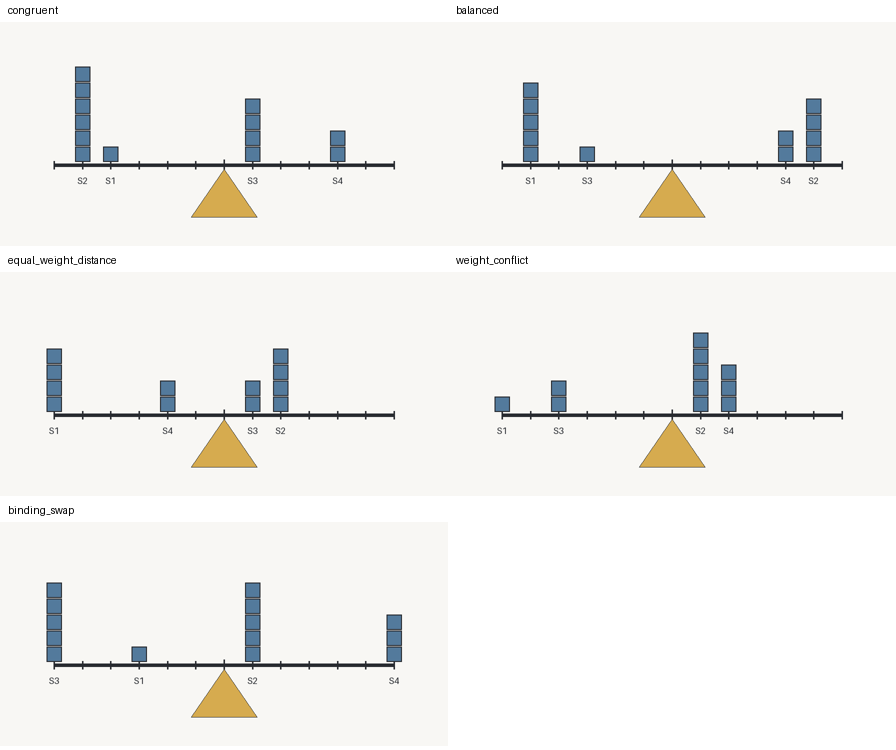

Example complete-variable prompt (no torque or correct answer supplied):

Answer this question using the supplied scene information.

Each square is one unit of weight. Distance is measured in tick intervals from the center pivot. Torque equals weight times distance. Total torque on a side is the sum over stacks on that side.

Stack IDs identify positions; they do not encode weight or distance. Use any supplied image and provided values. A field marked not provided supplies no numeric value.

Provided stack information:
S1: side=left; weight=1; distance=3
S2: side=right; weight=5; distance=1
S3: side=left; weight=5; distance=6
S4: side=right; weight=3; distance=6

Question: Which way will the balance scale tip?

Options:
A. equal
B. right side
C. left side

Do not explain your reasoning. Reply with exactly one option letter and nothing else. Valid replies are: A, B, C.


In [8]:
%%cell_progress 7/13 Generate, render and freeze paired scene inputs
cell_stage('Reading existing geometry manifests and snapshots')
excluded=load_history(PROJECT_ROOT,RUN_ROOT,SOURCE_HISTORY_RUN_ID,EXTRA_HISTORY_FILES,
    progress=lambda message:(print(message,flush=True),cell_stage(message)))
if PHASE=='validation':
    excluded |= geometries_in(read_json(RUN_ROOT/'shared/development/support.json'))
support_path=SHARED_ROOT/'support.json'
if support_path.exists():
    SUPPORT=read_json(support_path)
    assert SUPPORT['phase']==PHASE and SUPPORT['n_families']==N_FAMILIES
    FAMILIES=SUPPORT['families']
else:
    cell_stage('Generating mirror-disjoint physical families on CPU')
    FAMILIES=generate_families(N_FAMILIES,SEED+(0 if PHASE=='development' else 1),excluded,PHASE)
    SUPPORT=dict(schema=SCHEMA,phase=PHASE,n_families=N_FAMILIES,families=FAMILIES,
        geometry_exclusion_sha256=file_hash(RUN_ROOT/'historical_exclusion.json'),
        protocol_sha256=file_hash(SHARED_ROOT/'phase_protocol.json'))
    save_json(support_path,SUPPORT)
assert SUPPORT['geometry_exclusion_sha256']==file_hash(RUN_ROOT/'historical_exclusion.json')
assert SUPPORT['protocol_sha256']==file_hash(SHARED_ROOT/'phase_protocol.json')
validate_families(FAMILIES,excluded)
cell_stage('Rendering shared scenes and fixed stack IDs')
IMAGE_MANIFEST=render_images(FAMILIES,IMAGE_DIR)
freeze_inputs()


In [9]:
%%cell_progress 8/13 Check GPU and model access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select a GPU runtime with sufficient memory for full BF16.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login unavailable:', type(exc).__name__)


Check GPU and model access:  54%|#####3    | 7/13 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login unavailable: SecretNotFoundError


In [10]:
%%cell_progress 9/13 Load the model and freeze scoring protocol
cell_stage(f'Loading native BF16 {MODEL_KEY}')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()
adapter=HuggingFaceMultimodalAdapter(SPEC['model_id'],revision=SPEC['revision'],
    dtype='bfloat16',device_map='auto')
display(adapter.metadata)
init_runtime()


Load the model and freeze scoring protocol:  62%|######1   | 8/13 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f…dd9801',
 'resolved_revision': '373612cb4f…dd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Frozen candidate plans: {'prefix': [], 'token_by_label': {'A': 32, 'B': 33, 'C': 34}}
Direct-answer scoring; hidden reasoning disabled. Results do not measure a reasoning-enabled ceiling.


In [11]:
%%cell_progress 10/13 Run paired information-support conditions
ROWS=run_scoring()


Run paired information-support conditions:  69%|######9   | 9/13 [00:00<?, ?cell/s]

qwen27b / development: paired inputs:   0%|          | 0/1440 [00:00<?, ?forward/s]

In [12]:
%%cell_progress 11/13 Analyze physical errors and relationship pairs
SUMMARY,TESTS=complete_analysis(ROWS)


Analyze physical errors and relationship pairs:  77%|#######6  | 10/13 [00:00<?, ?cell/s]

,scope,condition,n_families,mean,lower,upper
0,all,image,32,0.4453,0.3698,0.5156
1,all,image_distance,32,0.4609,0.3854,0.5286
2,all,image_full,32,0.4635,0.3906,0.5312
3,all,image_weight,32,0.4271,0.3516,0.4948
4,all,legacy_image,32,0.4688,0.3932,0.5391
5,all,text_full,32,0.5443,0.4349,0.6510
6,congruent,image,4,0.7083,0.5833,0.8333
7,congruent,image_distance,4,0.7083,0.5833,0.8333
8,congruent,image_full,4,0.7083,0.5833,0.8333
9,congruent,image_weight,4,0.6250,0.5000,0.7500


,model,phase,comparison,metric,scope,n_families,mean,lower,upper,p_value,holm_within_model,inference_status
0,qwen27b,development,weight_support_all,correct,all,32,-0.0182,-0.0417,0.0026,0.1719,1.0,development_descriptive_only
1,qwen27b,development,distance_support_all,correct,all,32,0.0156,-0.0104,0.0469,0.4219,1.0,development_descriptive_only
2,qwen27b,development,full_support_all,correct,all,32,0.0182,-0.0052,0.0469,0.3125,1.0,development_descriptive_only
3,qwen27b,development,joint_support_interaction,correct,all,32,0.0208,-0.0130,0.0573,0.3359,1.0,development_descriptive_only
4,qwen27b,development,distance_equal_weight,correct,equal_weight_distance,8,0.0833,0.0208,0.1667,0.2500,1.0,development_descriptive_only
5,qwen27b,development,full_weight_conflict,correct,weight_conflict,8,0.0208,0.0000,0.0625,1.0000,1.0,development_descriptive_only
6,qwen27b,development,full_binding_pair,both_correct,binding_swap,8,-0.0417,-0.1250,0.0000,1.0000,1.0,development_descriptive_only


,condition,n,valid,agrees,agreement_all,agreement_valid
0,image,10,10,10,1.0,1.0
1,image_distance,10,10,10,1.0,1.0
2,image_full,10,10,10,1.0,1.0
3,image_weight,10,10,10,1.0,1.0
4,legacy_image,10,10,10,1.0,1.0
5,text_full,10,10,10,1.0,1.0


Development completed. Its estimates are exploratory; run the other model before freezing validation.


In [13]:
%%cell_progress 12/13 Combine the two planned models
combine_models()


Combine the two planned models:  85%|########4 | 11/13 [00:00<?, ?cell/s]

,model,phase,comparison,metric,scope,n_families,mean,lower,upper,p_value,holm_within_model,inference_status,holm_across_models_14_tests
0,gemma12b,development,weight_support_all,correct,all,32,-0.0885,-0.1589,-0.0338,0.0039,0.0234,development_descriptive_only,0.0508
1,gemma12b,development,distance_support_all,correct,all,32,0.0625,0.0234,0.1042,0.0061,0.0305,development_descriptive_only,0.0732
2,gemma12b,development,full_support_all,correct,all,32,0.1172,0.0391,0.1979,0.0114,0.0456,development_descriptive_only,0.1254
3,gemma12b,development,joint_support_interaction,correct,all,32,0.1432,0.0677,0.2266,0.0006,0.0042,development_descriptive_only,0.0084
4,gemma12b,development,distance_equal_weight,correct,equal_weight_distance,8,0.1458,0.0625,0.2292,0.0625,0.1875,development_descriptive_only,0.6250
5,gemma12b,development,full_weight_conflict,correct,weight_conflict,8,0.0833,-0.0833,0.2500,0.5312,1.0000,development_descriptive_only,1.0000
6,gemma12b,development,full_binding_pair,both_correct,binding_swap,8,0.0000,-0.1042,0.1250,1.0000,1.0000,development_descriptive_only,1.0000
7,qwen27b,development,weight_support_all,correct,all,32,-0.0182,-0.0417,0.0026,0.1719,1.0000,development_descriptive_only,1.0000
8,qwen27b,development,distance_support_all,correct,all,32,0.0156,-0.0104,0.0469,0.4219,1.0000,development_descriptive_only,1.0000
9,qwen27b,development,full_support_all,correct,all,32,0.0182,-0.0052,0.0469,0.3125,1.0000,development_descriptive_only,1.0000


In [14]:
%%cell_progress 13/13 Export complete or partial results
OUTPUT_ZIP=export_support()


Export complete or partial results:  92%|#########2| 12/13 [00:00<?, ?cell/s]

Export status: complete 
Drive: /content/drive/MyDrive/VisualTorque/results/visual_information_support_v1/main/VisualTorque_VisualInformationSupport_qwen27b_development_Output.zip 
Download: /content/VisualTorque_VisualInformationSupport_qwen27b_development_Output.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>